第 0 代發現更佳解，適應值：91340
第 0 代 | 最佳：91340.00 | 平均：127812.52
第 1 代發現更佳解，適應值：81305
第 2 代發現更佳解，適應值：71299
第 3 代發現更佳解，適應值：61284
第 4 代發現更佳解，適應值：51221
第 5 代發現更佳解，適應值：41256
第 6 代發現更佳解，適應值：41205
第 7 代發現更佳解，適應值：31157
第 8 代發現更佳解，適應值：21269
第 9 代發現更佳解，適應值：11188
第 10 代發現更佳解，適應值：11175
第 10 代 | 最佳：11175.00 | 平均：26202.68
第 11 代發現更佳解，適應值：1188
第 12 代發現更佳解，適應值：1175
第 13 代發現更佳解，適應值：1145
第 14 代發現更佳解，適應值：1116
第 15 代發現更佳解，適應值：1114
第 16 代發現更佳解，適應值：1096
第 18 代發現更佳解，適應值：1073
第 19 代發現更佳解，適應值：1056
第 20 代發現更佳解，適應值：1045
第 20 代 | 最佳：1045.00 | 平均：9688.12
第 21 代發現更佳解，適應值：1035
第 22 代發現更佳解，適應值：1024
第 24 代發現更佳解，適應值：1020
第 27 代發現更佳解，適應值：1000
第 29 代發現更佳解，適應值：999
第 30 代 | 最佳：999.00 | 平均：3612.32
第 32 代發現更佳解，適應值：979
第 35 代發現更佳解，適應值：950
第 37 代發現更佳解，適應值：945
第 39 代發現更佳解，適應值：943
第 40 代 | 最佳：943.00 | 平均：4758.32
第 41 代發現更佳解，適應值：941
第 42 代發現更佳解，適應值：940
第 43 代發現更佳解，適應值：939
第 46 代發現更佳解，適應值：938
第 50 代發現更佳解，適應值：932
第 50 代 | 最佳：932.00 | 平均：5555.68
第 53 代發現更佳解，適應值：928
第 58 代發現更佳解，適應值：926
第 59 代發現更佳解，適應值：924
第 60 代發現更佳解，適應值：920
第 60 代 | 最佳：920.

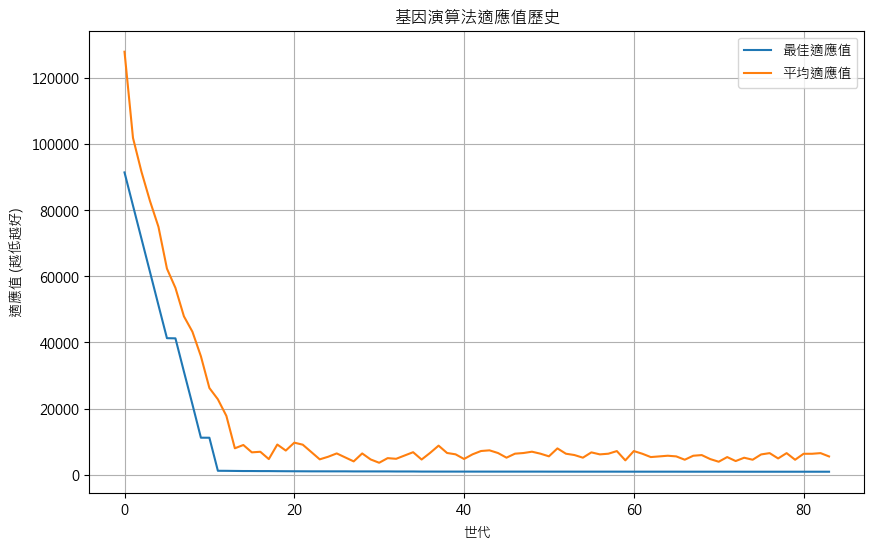


GA 結果最佳適應值 = 906
Tabu 第 1 代: 新全局最佳適應值 = 904
Tabu 第 2 代: 新全局最佳適應值 = 902
Tabu 第 3 代: 新全局最佳適應值 = 901
Tabu 第 4 代: 新全局最佳適應值 = 894
Tabu 第 7 代: 新全局最佳適應值 = 891
Tabu 第 8 代: 新全局最佳適應值 = 888
Tabu 第 9 代: 新全局最佳適應值 = 887
Tabu 第 10 代: 新全局最佳適應值 = 885
Tabu 第 11 代: 新全局最佳適應值 = 884
連續 10 次迭代無改善，提前終止 Tabu 搜索

最終排程結果:
   CART_ID  ORDER WIP_ID    ACTION  COMPLETE_TIME
0      C18      1    W37    PICKUP             21
1      C18      2    W14    PICKUP             35
2      C18      3    W37  DELIVERY             43
3      C18      4    W14  DELIVERY             46
4      C15      1    W32    PICKUP             16
..     ...    ...    ...       ...            ...
75     C09      4    W38  DELIVERY             46
76     C02      1    W39    PICKUP             23
77     C02      2    W19    PICKUP             28
78     C02      3    W39  DELIVERY             30
79     C02      4    W19  DELIVERY             35

[80 rows x 5 columns]

排程結果已保存至 'schedule_result.xlsx'

整合後最佳適應值 (淘汰訂單數*10000+行駛距離) = 884

----- 各 CA

In [2]:
import pandas as pd
import numpy as np
import random
import matplotlib.pyplot as plt
import matplotlib
from joblib import Parallel, delayed

# 設定中文字型避免中文亂碼
matplotlib.rcParams['font.sans-serif'] = ['Microsoft JhengHei','SimHei','Arial Unicode MS']
matplotlib.rcParams['axes.unicode_minus'] = False

# -------------------------------
# 讀取資料
df_cart = pd.read_excel("data.xlsx", sheet_name="CART")
df_wip  = pd.read_excel("data.xlsx", sheet_name="WIP")
df_xfer = pd.read_excel("data.xlsx", sheet_name="XFER_TIME")

# 建立 XFER_TIME 快速查表
xfer_dict = {}
for _, row in df_xfer.iterrows():
    if row["FROM"] not in xfer_dict:
        xfer_dict[row["FROM"]] = {}
    xfer_dict[row["FROM"]][row["TO"]] = row["XFER_TIME"]

# -------------------------------
# 可調整的參數
POP_SIZE         = 50       # 族群大小
GENERATIONS      = 500      # 進化世代數
ELITE_SIZE       = 1        # 精英保留數
MUTATION_RATE    = 0.4      # 突變率
TOURNAMENT_SIZE  = 10       # 錦標賽選擇樣本數
BATCH_CAPACITY   = 2        # 每台 CART 一次最多接受的訂單數

TABU_ITERATIONS  = 500      # 禁忌搜索迭代次數
TABU_TENURE      = 10       # 禁忌期限

# -------------------------------
# 修正函式：確保每台 CART 的訂單數不超過 BATCH_CAPACITY，且每個訂單只排入一次
def repair_chromosome(chromosome):
    assigned = set()
    for cart in chromosome:
        new_list = []
        for w in chromosome[cart]:
            if w not in assigned and len(new_list) < BATCH_CAPACITY:
                new_list.append(w)
                assigned.add(w)
        chromosome[cart] = new_list
    global_orders = set(df_wip["WIP_ID"].tolist())
    missing = list(global_orders - assigned)
    random.shuffle(missing)
    for order in missing:
        added = False
        for cart in chromosome:
            if len(chromosome[cart]) < BATCH_CAPACITY:
                chromosome[cart].append(order)
                assigned.add(order)
                added = True
                break
        if not added:
            cart = random.choice(list(chromosome.keys()))
            idx = random.randrange(len(chromosome[cart]))
            chromosome[cart][idx] = order
            assigned.add(order)
    return chromosome

# -------------------------------
# 基因初始族群產生：每台 CART 挑選訂單後隨機排列產生初始解
def init_population(pop_size):
    population = []
    wip_ids = df_wip["WIP_ID"].tolist()
    random.shuffle(wip_ids)
    cart_ids = df_cart["CART_ID"].tolist()
    base_assignment = {cart: [] for cart in cart_ids}
    for w in wip_ids:
        available = [c for c in cart_ids if len(base_assignment[c]) < BATCH_CAPACITY]
        if available:
            chosen = random.choice(available)
            base_assignment[chosen].append(w)
    for _ in range(pop_size):
        chromosome = {}
        for cart in cart_ids:
            orders_for_cart = base_assignment[cart].copy()
            random.shuffle(orders_for_cart)
            # 染色體只存訂單列表，固定使用 generate_mixed_sequence
            chromosome[cart] = orders_for_cart
        population.append(chromosome)
    return population

# -------------------------------
# 生成合法操作序列：依照訂單列表複製兩倍，第一次出現為 PICKUP，第二次為 DELIVERY
def generate_mixed_sequence(wip_list):
    if len(wip_list) == 0:
        return []
    tasks = wip_list * 2
    seen = {}
    sequence = []
    for w in tasks:
        if w not in seen:
            seen[w] = 1
            sequence.append(("pickup", w))
        else:
            sequence.append(("delivery", w))
    valid = True
    for w in wip_list:
        if sequence.index(("pickup", w)) > sequence.index(("delivery", w)):
            valid = False
            break
    if valid:
        return sequence
    else:
        seq = []
        for w in wip_list:
            seq.append(("pickup", w))
            seq.append(("delivery", w))
        return seq

# -------------------------------
# 評估單台 CART 的運作：根據操作序列計算超時訂單數和總行駛距離
def evaluate_cart(cart, wip_list):
    init_loc = df_cart.loc[df_cart["CART_ID"]==cart, "INIT_LOC"].values[0]
    current_loc = init_loc
    time_elapsed = 0
    distance = 0
    schedule = []
    rejections = 0
    if len(wip_list) == 0:
        return 0, 0, 0, []
    ops = generate_mixed_sequence(wip_list)
    for op, wip in ops:
        info = df_wip.loc[df_wip["WIP_ID"]==wip].iloc[0]
        if op == "pickup":
            loc = info["FROM"]
            d = xfer_dict[current_loc][loc]
            distance += d
            time_elapsed += d
            schedule.append({'wip_id': wip, 'action': 'PICKUP', 'location': loc, 'time': time_elapsed})
            current_loc = loc
        else:
            loc = info["TO"]
            d = xfer_dict[current_loc][loc]
            distance += d
            time_elapsed += d
            schedule.append({'wip_id': wip, 'action': 'DELIVERY', 'location': loc, 'time': time_elapsed})
            if time_elapsed > info["Remaining Q-Time"]:
                rejections += 1
            current_loc = loc
    return rejections, distance, time_elapsed, schedule

# -------------------------------
# fitness 函式：計算整體染色體的適應值，同時回傳各 CART 的詳細排程與指標
def fitness(chromosome):
    total_rejections = 0
    total_distance = 0
    cart_details = {}
    cart_metrics = {}
    for cart, orders in chromosome.items():
        orders = orders[:BATCH_CAPACITY]
        rej, dist, finish_time, sched = evaluate_cart(cart, orders)
        total_rejections += rej
        total_distance += dist
        cart_details[cart] = sched
        cart_metrics[cart] = {"rejections": rej, "distance": dist, "completion_time": finish_time}
    fit_val = total_rejections * 10000 + total_distance
    return fit_val, cart_details, cart_metrics

# -------------------------------
# 交配：對兩個父代染色體採取 CART 分半交配，然後利用 repair 修正
def crossover(p1, p2):
    child = {}
    cart_ids = list(p1.keys())
    random.shuffle(cart_ids)
    half = len(cart_ids) // 2
    assigned = set()
    for cart in cart_ids[:half]:
        child[cart] = p1[cart].copy()
        assigned.update(p1[cart])
    for cart in cart_ids[half:]:
        lst = [w for w in p2[cart] if w not in assigned]
        child[cart] = lst
        assigned.update(lst)
    child = repair_chromosome(child)
    return child

# -------------------------------
# 突變：隨機從兩台 CART 中交換一筆訂單
def mutate(chromosome, mutation_rate=MUTATION_RATE):
    if random.random() > mutation_rate:
        return chromosome
    mutated = {c: v.copy() for c, v in chromosome.items()}
    carts_list = list(mutated.keys())
    c1, c2 = random.sample(carts_list, 2)
    if mutated[c1] and mutated[c2]:
        i = random.randrange(len(mutated[c1]))
        j = random.randrange(len(mutated[c2]))
        mutated[c1][i], mutated[c2][j] = mutated[c2][j], mutated[c1][i]
    mutated = repair_chromosome(mutated)
    return mutated

# -------------------------------
# 錦標賽選擇
def tournament_selection(population, fitness_details, k=TOURNAMENT_SIZE):
    selected = random.sample(range(len(population)), k)
    best = min(selected, key=lambda i: fitness_details[i][0])
    return population[best]

# -------------------------------
# 主 GA 流程
# 修改後的 GA 主流程：若連續 10 個世代無改善則提前終止
def genetic_algorithm(pop_size=POP_SIZE, generations=GENERATIONS, elite_size=ELITE_SIZE):
    population = init_population(pop_size)
    best_history = []
    avg_history = []
    best_solution = None
    best_fit = float('inf')
    best_details = None
    best_metrics = None
    
    no_update_count = 0  # 連續未更新最佳解的計數器
    ga_update_threshold = 10  # 若連續 10 個世代無改善則終止
    
    for gen in range(generations):
        fits_details = [fitness(chrom) for chrom in population]
        fits = [fd[0] for fd in fits_details]
        details_list = [fd[1] for fd in fits_details]
        metrics_list = [fd[2] for fd in fits_details]
        
        best_idx = fits.index(min(fits))
        best_gen_fit = fits[best_idx]
        best_history.append(best_gen_fit)
        avg_history.append(sum(fits) / len(fits))
        
        # 如果本代得到更佳解則更新並重置未更新計數器，否則累計
        if best_gen_fit < best_fit:
            best_fit = best_gen_fit
            best_solution = population[best_idx]
            best_details = details_list[best_idx]
            best_metrics = metrics_list[best_idx]
            no_update_count = 0
            print(f"第 {gen} 代發現更佳解，適應值：{best_fit}")
        else:
            no_update_count += 1
            
        if no_update_count >= ga_update_threshold:
            print(f"連續 {ga_update_threshold} 個世代無改善，提前終止 GA 搜尋")
            break
        
        elite_indices = sorted(range(len(fits)), key=lambda i: fits[i])[:elite_size]
        new_population = [population[i] for i in elite_indices]
        while len(new_population) < pop_size:
            parent1 = tournament_selection(population, fits_details)
            parent2 = tournament_selection(population, fits_details)
            child = crossover(parent1, parent2) if random.random() < 0.8 else parent1.copy()
            child = mutate(child)
            new_population.append(child)
        population = new_population
        
        if gen % 10 == 0:
            print(f"第 {gen} 代 | 最佳：{best_gen_fit:.2f} | 平均：{sum(fits)/len(fits):.2f}")
    
    plt.figure(figsize=(10,6))
    plt.plot(best_history, label="最佳適應值")
    plt.plot(avg_history, label="平均適應值")
    plt.xlabel("世代")
    plt.ylabel("適應值 (越低越好)")
    plt.title("基因演算法適應值歷史")
    plt.legend()
    plt.grid(True)
    plt.savefig("fitness_history.png", dpi=300)
    plt.show()
    
    return best_solution, best_fit, best_details, best_metrics

# -------------------------------
# Tabu 搜索（保留原程式，可依需求修改）
# 產生大量鄰域候選解的函式，每個運算子重複 rep 次以擴大候選集合
def generate_neighbors(current_solution, rep=5):
    neighbors = []
    carts = list(current_solution.keys())
    
    # 跨 CART 交換運算（swap_cross）
    for _ in range(rep):
        for i in range(len(carts)):
            for j in range(i+1, len(carts)):
                cart1, cart2 = carts[i], carts[j]
                list1 = current_solution[cart1]
                list2 = current_solution[cart2]
                if len(list1) == 0 or len(list2) == 0:
                    continue
                idx1 = random.randrange(len(list1))
                idx2 = random.randrange(len(list2))
                neighbor = {c: v.copy() for c, v in current_solution.items()}
                neighbor[cart1][idx1], neighbor[cart2][idx2] = neighbor[cart2][idx2], neighbor[cart1][idx1]
                neighbor = repair_chromosome(neighbor)
                move = ("swap_cross", cart1, idx1, cart2, idx2)
                neighbors.append((neighbor, move))
    
    # 同一 CART 內部交換（swap_intra）
    for _ in range(rep):
        for cart in carts:
            orders = current_solution[cart]
            if len(orders) < 2:
                continue
            idx1, idx2 = random.sample(range(len(orders)), 2)
            neighbor = {c: v.copy() for c, v in current_solution.items()}
            neighbor[cart][idx1], neighbor[cart][idx2] = neighbor[cart][idx2], neighbor[cart][idx1]
            neighbor = repair_chromosome(neighbor)
            move = ("swap_intra", cart, idx1, idx2)
            neighbors.append((neighbor, move))
    
    # 插入運算 (Insertion Operator)
    for _ in range(rep):
        for cart in carts:
            orders = current_solution[cart]
            if len(orders) < 2:
                continue
            neighbor = {c: v.copy() for c, v in current_solution.items()}
            idx = random.randrange(len(neighbor[cart]))
            order = neighbor[cart].pop(idx)
            new_idx = random.randrange(len(neighbor[cart]) + 1)
            neighbor[cart].insert(new_idx, order)
            neighbor = repair_chromosome(neighbor)
            move = ("insertion", cart, idx, new_idx)
            neighbors.append((neighbor, move))
    
    # 區間反轉運算 (Reversal Operator)
    for _ in range(rep):
        for cart in carts:
            orders = current_solution[cart]
            if len(orders) < 2:
                continue
            idx1, idx2 = sorted(random.sample(range(len(orders)), 2))
            neighbor = {c: v.copy() for c, v in current_solution.items()}
            neighbor[cart][idx1:idx2+1] = list(reversed(neighbor[cart][idx1:idx2+1]))
            neighbor = repair_chromosome(neighbor)
            move = ("reversal", cart, idx1, idx2)
            neighbors.append((neighbor, move))
    
    # 跨 CART 隨機重排運算：將所有 CART 的訂單收集後重排，再依照 BATCH_CAPACITY 分配
    for _ in range(rep):
        def random_reorder_crosscart(solution):
            all_orders = []
            for cart in solution:
                all_orders.extend(solution[cart])
            random.shuffle(all_orders)
            new_solution = {}
            for cart in solution:
                new_solution[cart] = []
                for _ in range(BATCH_CAPACITY):
                    if all_orders:
                        new_solution[cart].append(all_orders.pop(0))
            return repair_chromosome(new_solution)
        neighbor = random_reorder_crosscart(current_solution)
        move = ("crosscart_random_reorder",)
        neighbors.append((neighbor, move))
        
    return neighbors


def shake_solution(current_solution):
    # 將所有 CART 的訂單完全收集後隨機重排，再全新分配
    all_orders = []
    for cart in current_solution:
        all_orders.extend(current_solution[cart])
    random.shuffle(all_orders)
    new_solution = {}
    for cart in current_solution:
        new_solution[cart] = []
        for _ in range(BATCH_CAPACITY):
            if all_orders:
                new_solution[cart].append(all_orders.pop(0))
    return repair_chromosome(new_solution)


# 改良後的 Tabu 搜索函式：加入上方多種鄰域運算，並在連續 40 次無改善時停止
def tabu_search(max_iterations=TABU_ITERATIONS, tabu_tenure=TABU_TENURE, initial_solution=None):
    if initial_solution is None:
        current_solution = repair_chromosome(init_population(1)[0])
    else:
        current_solution = {c: v.copy() for c, v in initial_solution.items()}
    best_solution = {c: v.copy() for c, v in current_solution.items()}
    best_fit, best_details, best_metrics = fitness(best_solution)
    tabu_list = {}
    carts = list(current_solution.keys())
    
    no_update_count = 0  # 連續未更新最佳解的計數器
    update_threshold = 10
    
    for it in range(1, max_iterations+1):
        neighbors = generate_neighbors(current_solution)
        if not neighbors:
            break
        
        # 利用平行運算評估所有鄰域解
        results = Parallel(n_jobs=-1)(
            delayed(lambda nb, mv: (nb, mv, fitness(nb)[0]))(nb, mv) for nb, mv in neighbors
        )
        results.sort(key=lambda x: x[2])
        found = False
        for neighbor, move, fit_val in results:
            # 若該 move 在 Tabu List 中且尚未過期，且該鄰域解品質不比目前最佳好，則跳過
            if move in tabu_list and it < tabu_list[move] and fit_val >= best_fit:
                continue
            best_neighbor = neighbor
            best_neighbor_move = move
            best_neighbor_fit = fit_val
            found = True
            break
        if not found:
            best_neighbor, best_neighbor_move, best_neighbor_fit = results[0]
        current_solution = best_neighbor
        tabu_list[best_neighbor_move] = it + tabu_tenure
        expired = [m for m, expiry in tabu_list.items() if expiry <= it]
        for m in expired:
            del tabu_list[m]
        
        # 更新最佳解與計數器
        if best_neighbor_fit < best_fit:
            best_solution = {c: v.copy() for c, v in current_solution.items()}
            best_fit = best_neighbor_fit
            no_update_count = 0
            print(f"Tabu 第 {it} 代: 新全局最佳適應值 = {best_fit}")
        else:
            no_update_count += 1
        
        if no_update_count >= update_threshold:
            print(f"連續 {update_threshold} 次迭代無改善，提前終止 Tabu 搜索")
            break
            
    final_fit, final_details, final_metrics = fitness(best_solution)
    return best_solution, final_fit, final_details, final_metrics

# -------------------------------
# 根據結果生成最終排程
def generate_schedule(details):
    output = []
    for cart, events in details.items():
        order = 1
        for ev in events:
            output.append([cart, order, ev['wip_id'], ev['action'], ev['time']])
            order += 1
    return pd.DataFrame(output, columns=["CART_ID", "ORDER", "WIP_ID", "ACTION", "COMPLETE_TIME"])

# -------------------------------
# 主執行流程：先 GA 後 Tabu 搜索
if __name__ == "__main__":
    best_sol_ga, best_fit_ga, best_det_ga, best_metrics_ga = genetic_algorithm()
    print(f"\nGA 結果最佳適應值 = {best_fit_ga}")

    best_sol, best_fit, best_det, best_metrics = tabu_search(initial_solution=best_sol_ga)

    final_schedule = generate_schedule(best_det)
    print("\n最終排程結果:")
    print(final_schedule)
    final_schedule.to_excel("schedule_result.xlsx", index=False)
    print("\n排程結果已保存至 'schedule_result.xlsx'")
    print(f"\n整合後最佳適應值 (淘汰訂單數*10000+行駛距離) = {best_fit}")

    print("\n----- 各 CART 指標 -----")
    total_rej = 0
    total_dist = 0
    max_time = 0
    for cart in sorted(best_metrics.keys()):
        metrics = best_metrics[cart]
        total_rej += metrics["rejections"]
        total_dist += metrics["distance"]
        if metrics["completion_time"] > max_time:
            max_time = metrics["completion_time"]
        print(f"{cart}：淘汰訂單數 = {metrics['rejections']}, 行駛距離 = {metrics['distance']}, 完成耗時 = {metrics['completion_time']}")
  
    print("\n---- 總計 ----")
    print(f"總淘汰訂單數 = {total_rej}")
    print(f"總行駛距離 = {total_dist}")
    print(f"所有 CART 最後完成時間 = {max_time}")